# Subproduto 2 - Integração e conciliação MES × SAP

## O problema, em uma imagem

Quando um equipamento quebra, **duas pessoas anotam o mesmo acontecimento em dois cadernos diferentes**:

- o operador anota no **MES** (sistema da Produção): "o AQUECIMENTO parou das 10:02 às 11:15, componente QMD";
- o mecânico anota no **SAP** (sistema da Manutenção): "ordem 1001695816, FORNO 1, PROBLEMA NO QMD, das 10:10 às 11:00".

Não existe um "número do chamado" comum aos dois cadernos. Então, para saber que essas duas anotações falam **do mesmo evento**, é preciso fazer como um detetive: comparar horários, nomes do equipamento e palavras do texto, e decidir se é o mesmo caso. Isso se chama **conciliação** (em inglês, *record linkage*: "ligar registros").

**Entrada:** as três bases geradas por `processamento_inicial.ipynb` (`mes_registros`, `mes_paradas`, `sap_ordens`).
O algoritmo fica no arquivo `conciliacao.py` (mesma pasta), para ser reaproveitado pelo dashboard do Subproduto 4 sem copiar código.

**O que se liga a quê:** a *parada* do MES (registros do mesmo equipamento já costurados no notebook anterior) com a *ordem* do SAP. Uma parada pode receber **várias** ordens (dois serviços feitos na mesma parada), mas cada ordem vai para **no máximo uma** parada.

**Resultado:** uma base de **eventos** com três tipos:

- `MES + SAP`: os dois cadernos contaram a mesma história (achamos o par);
- `MES sem SAP`: a máquina parou, mas não há ordem de manutenção correspondente;
- `SAP sem MES`: houve serviço de manutenção, mas não há parada correspondente.

Para cada evento conciliado, montamos a linha do tempo *parada → início do serviço → fim do serviço → máquina volta a produzir*.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import scripts.conciliacao as cc
from scripts.conciliacao import P

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

# Configrações de cores e estilo do matplotlib - Só para ficar bonitinho :)
COR_CLASSE = {"MES + SAP": "#2a78d6", "MES sem SAP": "#fdb814", "SAP sem MES": "#0f2185"}
COR_FONTE = {"MES": COR_CLASSE["MES sem SAP"], "SAP": COR_CLASSE["SAP sem MES"]}   # mesma lógica de cor
COR_CONF = {"alta": "#1c5cab", "media": "#3987e5", "baixa": "#86b6ef", "sem correspondencia": "#c9c8c2"}
TXT, TXT2, GRADE = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRADE, "axes.labelcolor": TXT2,
    "xtick.color": TXT2, "ytick.color": TXT2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

IN_DIR = Path("./data/processed/limpeza")
OUT_DIR = Path("./data/processed/conciliacao"); OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("./figuras"); FIG_DIR.mkdir(exist_ok=True)

mes, paradas, sap = cc.carregar(IN_DIR)
print(f"{len(paradas)} paradas MES | {sap['valido'].sum()} ordens SAP válidas")

1501 paradas MES | 1547 ordens SAP válidas


## 1. O que os dados mostram antes de qualquer regra

Antes de inventar um método, olhamos os dados. Três fatos medidos guiaram o desenho:

1. **Máquinas B, C e D** se comportam como dados gerados por computador (dados "de laboratório"): em ~90% das ordens existe uma parada do mesmo equipamento a menos de 30 min, e o SAP começa, em mediana, **9 min depois** do MES. O texto do SAP descreve o componente do MES por extenso (`ALM-SEN` ↔ "SENSOR ALIMENTADOR"). Nelas, o par é quase óbvio.
2. **Máquina A** é a máquina real e se comporta como dado real, isto é, bagunçado: só 16% das ordens têm parada a menos de 30 min; os horários do SAP vêm **arredondados** (10:00, 10:15...); e os dois sistemas usam **nomes diferentes** para o mesmo equipamento: o SAP diz `FORNO 1`, o MES diz `AQUECIMENTO` ou `DISCO`. Além disso, 80 ordens só dizem "MAQUINA A", sem detalhar o equipamento.
3. Em compensação, o texto do SAP da A cita o **código do componente do MES** literalmente em ~300 das 524 ordens (`QMD`, `RDFD`, `PCTDR`, `ESTRT`, `LONA`). É uma pista valiosa.

**Consequência:** nenhuma pista sozinha resolve. Só o horário falha na A (horários arredondados); uma tabela de tradução escrita à mão ("FORNO 1 = AQUECIMENTO") falha porque FORNO 1 às vezes é AQUECIMENTO e às vezes é DISCO. Por isso o método **combina as três pistas** e **aprende sozinho** as traduções de vocabulário a partir dos próprios dados.

## 2. Método

### 2.1 A ideia geral: uma nota de "parecença" para cada par

Para cada ordem do SAP, listamos as paradas do MES **da mesma máquina** que aconteceram perto dela no tempo (a até `JANELA_MAX_MIN` minutos). Cada par (ordem, parada) recebe uma **nota de 0 a 1**, o *score*, que diz o quanto eles parecem ser o mesmo evento:

$$\text{score} = 0{,}50\,S_{\text{tempo}} + 0{,}25\,S_{\text{equip}} + 0{,}25\,S_{\text{comp}}$$


**Por que o horário vale mais:** é a única pista que existe em **todos** os pares. Equipamento e texto às vezes não dizem nada ("MAQUINA A", "FALHA"). Mas o horário sozinho não basta, porque duas paradas podem acontecer ao mesmo tempo em equipamentos diferentes: é aí que as outras duas pistas desempatam.

### 2.2 As três pistas

| Pista | Como é medida | Em palavras simples |
|---|---|---|
| $S_{\text{tempo}}$ | $0{,}4\cdot \text{cont}$ $+\;0{,}3\,e^{-\text{gap}/30}+0{,}3\,e^{-\lvert\Delta\text{início}\rvert/60}$ | Mistura três medidas: (1) **contenção** = quanto dos dois intervalos se sobrepõe, dividido pelo intervalo menor (1 = um está inteiro dentro do outro); (2) o **vão** entre eles, se não se encostam; (3) a **diferença entre os horários de início**. |
| $S_{\text{equip}}$ | $P(\text{equip}_{\text{MES}} \mid \text{descrição}_{\text{SAP}})$ aprendida | "Quando o SAP escreve FORNO 1, com que frequência o MES chama esse mesmo evento de AQUECIMENTO?" A resposta é aprendida dos dados, sem tabela manual. |
| $S_{\text{comp}}$ | classificador *Naive Bayes* sobre as palavras do texto; código citado literalmente = 1 | "Dadas as palavras do texto do SAP, qual componente do MES é o mais provável?" Se o texto cita o código exato do componente, a nota é máxima. |

**$e^{-\text{gap}/30}$:** uma curva que começa em 1 e vai caindo suavemente à medida que a distância aumenta. Vão de 0 min → nota 1; vão de 30 min → ≈ 0,37; vão de 90 min → ≈ 0,05. A probabilidade de se tratar do mesmo evento cai rápido com o tempo, mas não é zero: uma parada pode ser registrada no MES e só depois a ordem é aberta no SAP.

**O que é Naive Bayes:** um método clássico para "adivinhar a categoria de um texto" (é o mesmo princípio dos primeiros filtros de spam de e-mail). Ele aprende, a partir de exemplos, quais palavras costumam aparecer com cada componente e combina as pistas de todas as palavras. Assim, "SENSOR" sozinho aponta para vários componentes, mas "SENSOR" + "ALIMENTADOR" juntos apontam para `ALM-SEN`. O "naive" (ingênuo) é porque ele trata cada palavra como uma pista independente, uma simplificação que funciona bem para textos curtos.

### 2.3 Como o método aprende sem gabarito: as "âncoras"

Para aprender "FORNO 1 costuma ser AQUECIMENTO", precisaríamos de exemplos já resolvidos, e **não temos gabarito**. A solução foi usar os casos **tão óbvios que o horário sozinho já resolve**, chamados de **âncoras**. Um par é âncora quando:

- os horários se sobrepõem em pelo menos 50% do intervalo menor;
- os inícios estão a até 60 min um do outro;
- a ordem dura menos de 24 h;
- e é o **único** candidato da ordem nessas condições (sem concorrente).

**Analogia:** é como aprender um idioma novo olhando primeiro as placas bilíngues. Nas placas óbvias ("SAÍDA / EXIT") aprendemos o vocabulário; depois usamos esse vocabulário para entender as frases difíceis. Aqui, as âncoras são as placas bilíngues entre o "idioma do SAP" e o "idioma do MES".

Dois cuidados no aprendizado:

- **Suavização de Laplace:** se uma palavra apareceu só uma vez, não queremos concluir que ela "sempre" indica um componente. A suavização soma uma contagem pequena a todas as opções, como dar a cada candidato um "voto de cortesia". Isso evita certezas absurdas baseadas em um exemplo só.
- **Deixar-um-de-fora (*leave-one-out*):** quando o método avalia uma âncora, ele **tira essa âncora** da tabela de aprendizado. É como um professor que não deixa o aluno corrigir a própria prova: a âncora não vota em si mesma.

O método não depende dos nomes desta base. Na fábrica real, com outros nomes, ele reaprende o vocabulário sozinho.

### 2.4 De probabilidade a nota: quando a pista é fraca, ela fica neutra

Uma probabilidade aprendida é transformada em nota por

$$S = 0{,}5 + (r - 0{,}5)\cdot\text{inform}$$

em que $r$ = probabilidade do candidato ÷ probabilidade do candidato mais provável, e *inform* mede o quanto a pista é **concentrada** (0 = aponta igualmente para todos; 1 = aponta para um só).

**Em palavras simples:** se a ordem diz só "MAQUINA A", essa pista não ajuda a escolher entre AQUECIMENTO e DISCO. Em vez de punir ou favorecer alguém, a nota fica **neutra em 0,5**, como um jurado que se abstém. Só pistas informativas empurram a nota para cima ou para baixo.

### 2.5 Escolha do par e nível de confiança

Cada ordem vai para a parada de maior nota. A nota define um "semáforo" de confiança:

| Confiança | Regra | Leitura |
|---|---|---|
| alta | score ≥ 0,75 | as pistas concordam fortemente |
| média | 0,60 ≤ score < 0,75 | provável |
| baixa | 0,45 ≤ score < 0,60, ou ordem com mais de 24 h de calendário | possível, mas precisa de conferência. Ordens longas ficam aqui porque, durando dias, "se sobrepõem" a muitas paradas e o horário deixa de discriminar. |
| sem correspondência | score < 0,45 ou nenhuma parada na janela | o método **não força** um par |
| **ambíguo** (marcação extra) | a 2ª melhor parada fica a menos de 0,05 da 1ª | empate técnico entre dois candidatos |

As ordens de confiança baixa e as ambíguas formam a **fila de revisão**: o algoritmo propõe, uma pessoa que conhece o equipamento confirma. É o mesmo princípio de um corretor ortográfico: ele sublinha, mas quem decide é você.

In [3]:
pares, vinculo = cc.conciliar(mes, paradas, sap)
eventos, vinculo = cc.consolidar(mes, paradas, sap, vinculo)

print(f"Pares candidatos avaliados: {len(pares)}  |  âncoras: {pares['ancora'].sum()}")
pd.crosstab(vinculo["maquina"], vinculo["confianca"], margins=True, margins_name="Total")[
    ["alta", "media", "baixa", "sem correspondencia", "Total"]]

Pares candidatos avaliados: 3003  |  âncoras: 861


confianca,alta,media,baixa,sem correspondencia,Total
maquina,,,,,
A,45,121,68,287,521
B,394,51,7,25,477
C,200,0,1,15,216
D,299,10,3,21,333
Total,938,182,79,348,1547


**O que a saída mostra:** foram avaliados 3.003 pares candidatos, dos quais 861 eram âncoras. Nas máquinas B–D quase tudo cai em confiança alta. Na máquina A, a maior parte fica em média/baixa ou sem correspondência, exatamente o que se esperava dos dados reais e bagunçados.

### 2.1 O vocabulário que o algoritmo aprendeu para a máquina A

Ninguém escreveu esta tabela: ela saiu das âncoras. Cada linha é um nome do SAP; cada coluna, um equipamento do MES; o número é a **porcentagem** das âncoras daquele nome do SAP que caíram em cada equipamento do MES.

Na linha "FORNO 1", ver 43 em AQUECIMENTO e 38 em DISCO quer dizer que, quando o SAP escreve "FORNO 1", o MES chamou o mesmo evento de AQUECIMENTO em 43% das vezes e de DISCO em 38%. É um **dicionário bilíngue com graus de certeza**.

Esse dicionário é também um produto em si: uma proposta de tradução SAP → MES que a Engenharia pode validar e corrigir.

In [4]:
anc_A = pares[pares["ancora"] & (pares["maquina"] == "A")]
depara = (pd.crosstab(anc_A["descricao_equip"], anc_A["equipamento"], normalize="index") * 100).round(0)
depara.insert(0, "n_ancoras", anc_A["descricao_equip"].value_counts())
depara.sort_values("n_ancoras", ascending=False)

equipamento,n_ancoras,AQUECIMENTO,DISCO,ESTACAO FIM,FACAO,FORNO 1,LONAS,MECANISMO,ROLOS
descricao_equip,,,,,,,,,
LONAS,22,9.0,36.0,0.0,0.0,0.0,50.0,0.0,5.0
FORNO 1,21,43.0,38.0,0.0,0.0,5.0,0.0,0.0,14.0
MAQUINA A,16,56.0,25.0,0.0,6.0,0.0,0.0,0.0,12.0
ROLOS,13,15.0,38.0,8.0,0.0,0.0,0.0,8.0,31.0
FORNO 2,9,44.0,22.0,0.0,0.0,0.0,22.0,0.0,11.0
AQUECIMENTO,5,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
FACAO,5,0.0,0.0,0.0,80.0,0.0,0.0,0.0,20.0
DISCO,4,0.0,75.0,0.0,0.0,0.0,25.0,0.0,0.0
ESTACAO FIM,1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Distribuição do score

O gráfico abaixo é um **histograma**: o eixo horizontal é a nota (de 0 a 1) dividida em faixas, e a altura de cada barra é quantas ordens tiraram nota naquela faixa. As cores seguem o semáforo de confiança, e as linhas tracejadas marcam os limites 0,45 / 0,60 / 0,75.

Nas máquinas B–D a distribuição tem **dois picos** (é "bimodal"): ou a ordem tem um par claro (nota ≈ 0,9) ou não tem candidato nenhum. Quase não há meio-termo. Na máquina A as notas se **espalham** pelo meio, que é a tradução numérica de "os dois sistemas contam histórias diferentes".

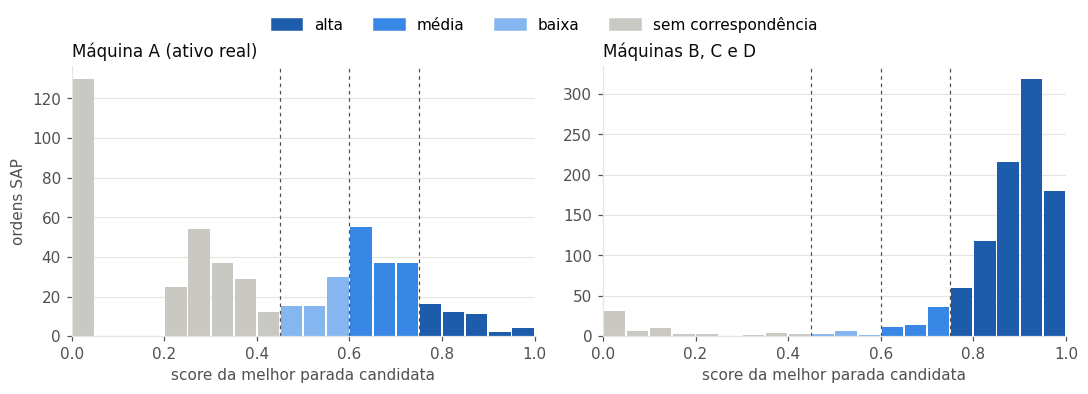

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
bins = np.arange(0, 1.0001, 0.05)
for ax, (nome, sel) in zip(axes, [("Máquina A (ativo real)", vinculo["maquina"] == "A"),
                                  ("Máquinas B, C e D", vinculo["maquina"] != "A")]):
    sc = vinculo.loc[sel, "score"]
    cont, _ = np.histogram(sc, bins=bins)
    meio = (bins[:-1] + bins[1:]) / 2
    cor = [COR_CONF["alta"] if m >= P["LIMIAR_ALTA"] else COR_CONF["media"] if m >= P["LIMIAR_MEDIA"]
           else COR_CONF["baixa"] if m >= P["LIMIAR_BAIXA"] else COR_CONF["sem correspondencia"] for m in meio]
    ax.bar(meio, cont, width=0.046, color=cor)
    for lim in (P["LIMIAR_BAIXA"], P["LIMIAR_MEDIA"], P["LIMIAR_ALTA"]):
        ax.axvline(lim, color=TXT2, lw=0.8, ls=(0, (3, 3)))
    ax.set_title(nome, loc="left", color=TXT, fontsize=11)
    ax.set_xlabel("score da melhor parada candidata"); ax.set_xlim(0, 1)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("ordens SAP")
handles = [plt.Rectangle((0, 0), 1, 1, color=COR_CONF[k]) for k in COR_CONF]
fig.legend(handles, ["alta", "média", "baixa", "sem correspondência"], loc="upper center",
           ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
fig.savefig(FIG_DIR / "01_distribuicao_score.png", bbox_inches="tight")
plt.show()

## 4. Base consolidada de eventos

Uma linha por evento. As colunas se organizam em grupos:

- `classe`, `confianca`, `score`, `revisar`, `ambiguo`: o resultado da conciliação e o quanto confiamos nele;
- `mes_inicio`, `mes_fim`, `indisponibilidade_h`: a visão da **Produção** (quanto tempo a máquina ficou parada);
- `sap_inicio`, `sap_fim`, `atuacao_h`, `atuacao_na_parada_h`: a visão da **Manutenção** (quanto tempo durou o serviço; e só a parte do serviço que caiu dentro da parada). Se a parada recebeu várias ordens, elas também são somadas pela "união", sem contar duas vezes o tempo sobreposto;
- `espera_ate_atuacao_min`, `retomada_apos_atuacao_min`, `dif_duracao_h`, `divergencia_duracao`: a linha do tempo do evento e as diferenças entre os dois cadernos;
- `ids_registro_mes`, `ordens`: as "etiquetas de rastreio" até a linha original de cada base.

O gráfico a seguir mostra, para cada máquina, a fatia de eventos de cada classe (barra inteira = 100% dos eventos da máquina; o número dentro é a quantidade).

In [6]:
resumo = (eventos.groupby(["maquina", "classe"])
          .agg(eventos=("id_evento", "size"),
               horas_MES=("indisponibilidade_h", "sum"),
               horas_SAP=("atuacao_h", "sum"))
          .round(1).unstack("classe", fill_value=0))
resumo

eventos                         horas_MES                          \
classe  MES + SAP MES sem SAP SAP sem MES MES + SAP MES sem SAP SAP sem MES   
maquina                                                                       
A             141         261         287     418.9       186.8         0.0   
B             441          86          25     281.2        38.4         0.0   
C             195          37          15     472.5        40.6         0.0   
D             297          43          21     477.6        40.6         0.0   

        horas_SAP                          
classe  MES + SAP MES sem SAP SAP sem MES  
maquina                                    
A          1035.9         0.0       443.8  
B           274.2         0.0        17.7  
C           461.7         0.0        46.0  
D           460.2         0.0        34.6

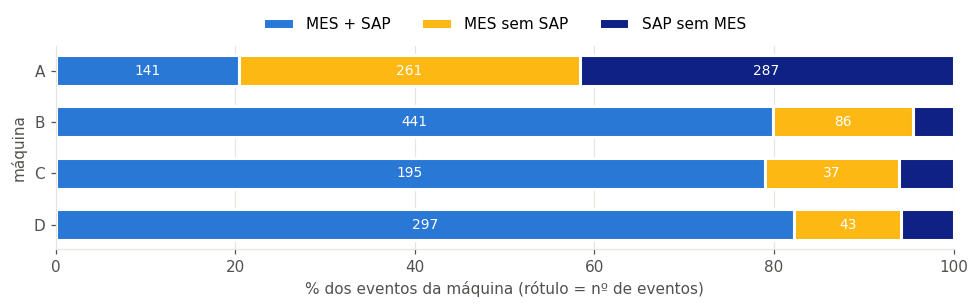

In [7]:
cont = pd.crosstab(eventos["maquina"], eventos["classe"])[list(COR_CLASSE)]
pct = cont.div(cont.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 2.9))
esq = np.zeros(len(pct))
for classe in COR_CLASSE:
    v = pct[classe].to_numpy()
    ax.barh(pct.index, v, left=esq, color=COR_CLASSE[classe], height=0.6,
            edgecolor="white", linewidth=2, label=classe)
    for i, (x0, w, n) in enumerate(zip(esq, v, cont[classe])):
        if w >= 7:
            ax.text(x0 + w / 2, i, f"{n}", ha="center", va="center", color="white", fontsize=9)
    esq += v
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("% dos eventos da máquina (rótulo = nº de eventos)")
ax.set_ylabel("máquina"); ax.grid(axis="y", visible=False)
ax.legend(ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
fig.savefig(FIG_DIR / "02_classes_por_maquina.png", bbox_inches="tight")
plt.show()

### 4.1 Por que um evento não concilia

Para cada evento sem par, o método sugere um **motivo provável** (por exemplo, "ajuste curto: provável ação do próprio operador", ou "quebra sem ordem: lacuna de apontamento na manutenção").

O motivo é uma **hipótese de trabalho** para orientar a investigação, como o "diagnóstico provável" de um médico antes dos exames. Não é uma conclusão.

In [8]:
sem_par = eventos[eventos["classe"] != "MES + SAP"]
pd.crosstab(sem_par["motivo_sem_par"], sem_par["maquina"], margins=True, margins_name="Total")

maquina,A,B,C,D,Total
motivo_sem_par,,,,,
ajuste curto: provável ação do próprio operador,131,63,12,20,226
ajuste longo sem ordem: verificar,44,14,13,14,85
nenhuma parada na janela: intervenção sem parada ou parada não apontada no MES,130,11,9,10,160
"parada próxima, mas incompatível (equipamento/texto): revisar",157,14,6,11,188
quebra sem ordem: lacuna de apontamento na manutenção,86,9,12,9,116
Total,548,111,52,64,775


## 5. Divergências entre os sistemas

Para os eventos em que os dois cadernos foram ligados (`MES + SAP`), comparamos o que cada um diz:

- **espera até atuação**: quantos minutos se passaram entre a parada (MES) e o início do serviço (SAP). Valor **negativo** significa que o SAP diz que o serviço começou **antes** de a máquina parar, o que é fisicamente estranho e indica horário anotado depois, de memória, ou arredondado;
- **duração**: se o SAP registra mais ou menos tempo do que o MES;
- **possível duplicidade no SAP** e o tamanho da **fila de revisão**.

In [9]:
conc = eventos[eventos["classe"] == "MES + SAP"]

div = pd.DataFrame({
    "eventos conciliados": conc.groupby("maquina").size(),
    "espera até atuação (mediana, min)": conc.groupby("maquina")["espera_ate_atuacao_min"].median(),
    "SAP começa >15 min antes da parada": conc.groupby("maquina")["sap_antes_da_parada"].sum(),
    "duração: SAP maior": conc[conc["divergencia_duracao"] == "SAP maior"].groupby("maquina").size(),
    "duração: MES maior": conc[conc["divergencia_duracao"] == "MES maior"].groupby("maquina").size(),
    "possível duplicidade SAP": conc.groupby("maquina")["possivel_duplicidade_sap"].sum(),
    "fila de revisão": conc.groupby("maquina")["revisar"].sum(),
}).fillna(0).round(1)
div

C:\Users\girle\AppData\Local\Temp\ipykernel_10284\2472778002.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  }).fillna(0).round(1)


,eventos conciliados,"espera até atuação (mediana, min)",SAP começa >15 min antes da parada,duração: SAP maior,duração: MES maior,possível duplicidade SAP,fila de revisão
maquina,,,,,,,
A,141,-11.0,66,66,35,5,63
B,441,8.0,4,13,22,0,8
C,195,10.0,0,1,1,0,1
D,297,10.0,1,3,7,0,3


### Como ler o gráfico de caixa (*boxplot*) abaixo

Cada máquina tem uma "caixa" que resume centenas de valores de uma vez:

- a **linha grossa** dentro da caixa é a mediana (o valor do meio);
- a **caixa** vai do 1º quartil ao 3º quartil, ou seja, contém **a metade central** dos eventos;
- as **hastes** mostram até onde vão os valores "normais";
- os **pontinhos** soltos são casos fora do comum.

Os valores foram cortados em ±120 min só para o gráfico caber na tela; usamos apenas os vínculos de confiança alta e média.

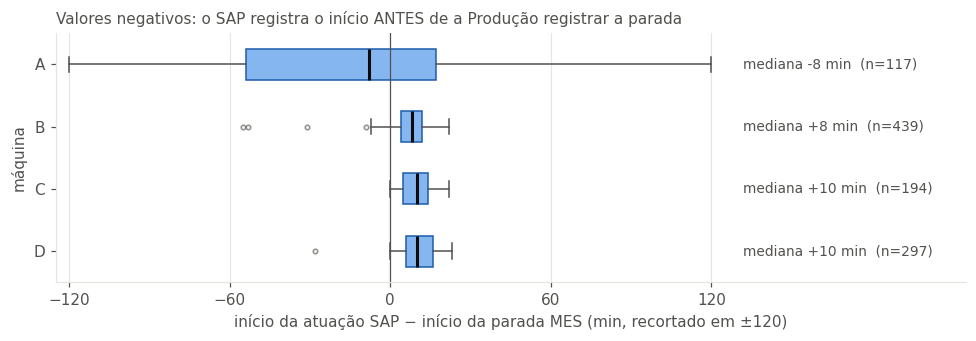

In [10]:
# Tempo entre a parada (MES) e o início da atuação (SAP) — proxy do tempo de resposta
fig, ax = plt.subplots(figsize=(9, 3.2))
dados = [conc.loc[(conc["maquina"] == m) & conc["confianca"].isin(["alta", "media"]),
                  "espera_ate_atuacao_min"].clip(-120, 120) for m in "ABCD"]
kw = {"orientation": "horizontal"} if tuple(map(int, plt.matplotlib.__version__.split(".")[:2])) >= (3, 10) \
     else {"vert": False}
bp = ax.boxplot(dados, **kw, widths=0.5, patch_artist=True,
                showfliers=True, flierprops=dict(marker="o", markersize=3, markerfacecolor=GRADE,
                                                  markeredgecolor=TXT2, alpha=0.6),
                medianprops=dict(color=TXT, lw=2), boxprops=dict(facecolor=COR_CONF["baixa"],
                                                                 edgecolor=COR_CONF["alta"]),
                whiskerprops=dict(color=TXT2), capprops=dict(color=TXT2))
ax.set_yticks([1, 2, 3, 4], list("ABCD"))
ax.axvline(0, color=TXT2, lw=0.8)
for i, d in enumerate(dados, start=1):
    ax.text(132, i, f"mediana {d.median():+.0f} min  (n={len(d)})", va="center", fontsize=9, color=TXT2)
ax.invert_yaxis(); ax.set_xlim(-125, 215); ax.set_xticks(range(-120, 121, 60))
ax.set_xlabel("início da atuação SAP − início da parada MES (min, recortado em ±120)")
ax.set_ylabel("máquina"); ax.grid(axis="y", visible=False)
ax.set_title("Valores negativos: o SAP registra o início ANTES de a Produção registrar a parada",
             loc="left", fontsize=10, color=TXT2)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_espera_ate_atuacao.png", bbox_inches="tight")
plt.show()

## 6. Linha do tempo de um evento

Um evento conciliado é decomposto em quatro instantes, separando o tempo em que **a máquina ficou sem produzir** (MES) do tempo em que **a manutenção trabalhou** (SAP):

`t0` a máquina para → `t1` começa o serviço → `t2` termina o serviço → `t3` a máquina volta a produzir

É como uma ida ao pronto-socorro. `t0` é a hora em que você chega; `t1`, a hora em que o médico começa a te atender; `t2`, a hora em que o atendimento termina; `t3`, a hora em que você recebe alta. O tempo entre `t0` e `t1` é a espera; entre `t2` e `t3`, a liberação.

Ainda **não existe** o instante em que alguém chamou a manutenção (hoje o chamado é verbal). Quando o acionamento digital do Subproduto 1 existir, ele entra como `t0'` entre `t0` e `t1` e separa *tempo até chamar* de *tempo até ser atendido*.

Nos gráficos abaixo, cada barra é um registro: em amarelo, a parada e os registros do MES; em azul escuro, as ordens do SAP. As linhas tracejadas verticais marcam `t0`, `t1`, `t2` e `t3`. Mostramos um exemplo "limpo" (máquina B) e um exemplo real com várias ordens (máquina A).

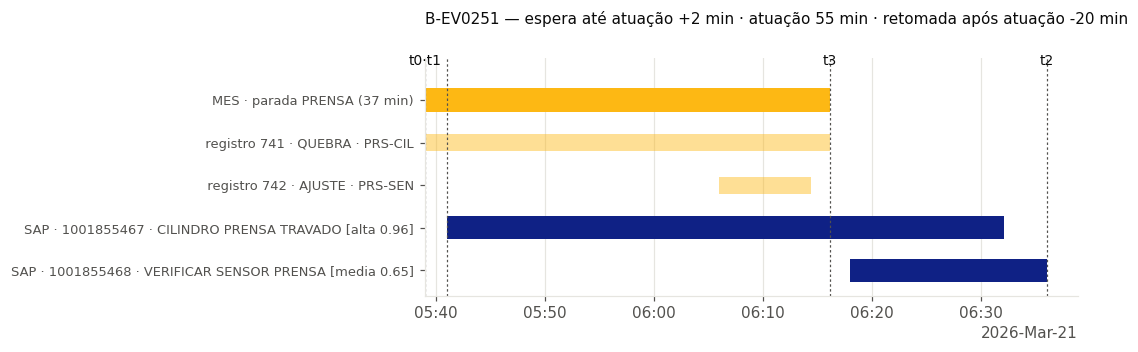

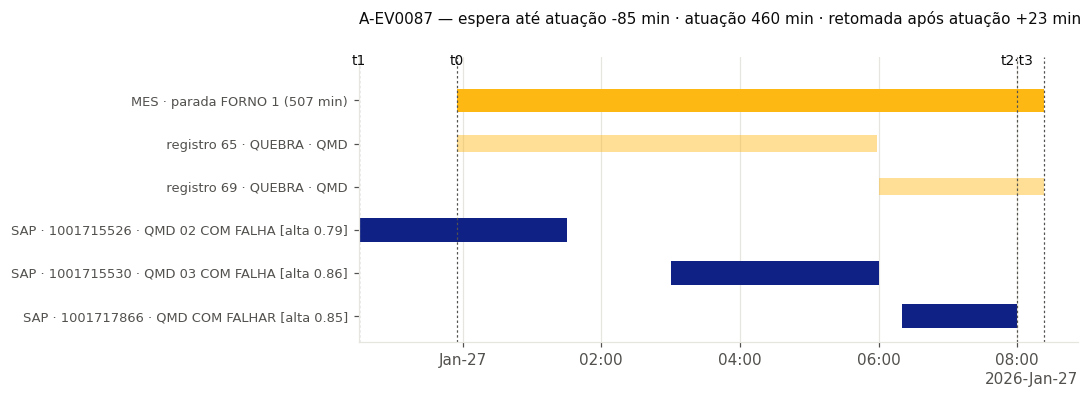

In [11]:
def linha_do_tempo(id_evento, ax=None):
    e = eventos.set_index("id_evento").loc[id_evento]
    ords = vinculo[vinculo["n_ordem"].astype(str).isin(str(e["ordens"]).split(","))].sort_values("inicio")
    regs = mes[mes["id_registro"].isin([int(x) for x in str(e["ids_registro_mes"]).split(",")])].sort_values("inicio")

    if ax is None:
        _, ax = plt.subplots(figsize=(10, 1.2 + 0.42 * (len(regs) + len(ords) + 1)))
    y, rot = 0, []
    ax.barh(y, e["mes_fim"] - e["mes_inicio"], left=e["mes_inicio"], height=0.55, color=COR_FONTE["MES"])
    rot.append(f"MES · parada {e['equipamento_mes']} ({e['indisponibilidade_h']*60:.0f} min)")
    for _, r in regs.iterrows():
        y += 1
        ax.barh(y, r["fim"] - r["inicio"], left=r["inicio"], height=0.4, color=COR_FONTE["MES"], alpha=0.45)
        rot.append(f"   registro {r['id_registro']} · {r['familia']} · {r['componente']}")
    for _, o in ords.iterrows():
        y += 1
        ax.barh(y, o["fim"] - o["inicio"], left=o["inicio"], height=0.55, color=COR_FONTE["SAP"])
        texto = str(o["texto_padronizado"])[:34]
        rot.append(f"SAP · {o['n_ordem']} · {texto} [{o['confianca']} {o['score']:.2f}]")

    marcos = [("t0", e["mes_inicio"]), ("t1", e["sap_inicio"]), ("t2", e["sap_fim"]), ("t3", e["mes_fim"])]
    # marcos muito próximos dividem o mesmo rótulo
    ini_x = min(t for _, t in marcos); vao = max(t for _, t in marcos) - ini_x
    rotulos = []
    for nome, t in sorted(marcos, key=lambda x: x[1]):
        ax.axvline(t, color=TXT2, lw=0.8, ls=(0, (2, 2)))
        if rotulos and (t - rotulos[-1][1]) < 0.04 * vao:
            rotulos[-1][0] += f"·{nome}"
        else:
            rotulos.append([nome, t])
    for nome, t in rotulos:
        ax.text(t, -0.75, nome, ha="center", va="bottom", fontsize=9, color=TXT)
    ax.set_yticks(range(len(rot)), rot, fontsize=8.5)
    ax.invert_yaxis(); ax.set_ylim(len(rot) - 0.4, -1.0)
    loc = mdates.AutoDateLocator(maxticks=8)
    ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{id_evento} — espera até atuação {e['espera_ate_atuacao_min']:+.0f} min · "
                 f"atuação {e['atuacao_h']*60:.0f} min · retomada após atuação {e['retomada_apos_atuacao_min']:+.0f} min",
                 loc="left", fontsize=10, color=TXT, pad=22)
    return ax

# exemplo "limpo" (B) e exemplo real com várias ordens (A)
ex_B = conc[(conc["maquina"] == "B") & (conc["n_ordens"] == 2) & (conc["confianca"] == "alta")]["id_evento"].iloc[3]
ex_A = conc[(conc["maquina"] == "A") & (conc["n_ordens"].between(2, 3)) & (conc["confianca"] == "alta")]["id_evento"].iloc[1]

for ex, arq in [(ex_B, "04_linha_do_tempo_B.png"), (ex_A, "05_linha_do_tempo_A.png")]:
    ax = linha_do_tempo(ex)
    ax.figure.tight_layout()
    ax.figure.savefig(FIG_DIR / arq, bbox_inches="tight")
    plt.show()

### 6.1 Um dia da máquina A nas duas visões (21/03, até 06:00 do dia seguinte)

Faixa de cima: as paradas registradas no MES, uma linha por equipamento. Faixa de baixo: as ordens do SAP. Cada traço diagonal liga uma ordem à parada que o algoritmo escolheu para ela, colorido pelo nível de confiança.

Pense nisso como **colocar lado a lado as anotações do operador e do mecânico do mesmo dia**, com setas mostrando "isto aqui é a mesma coisa que aquilo ali". É a visão que a reunião diária da fábrica hoje não tem.

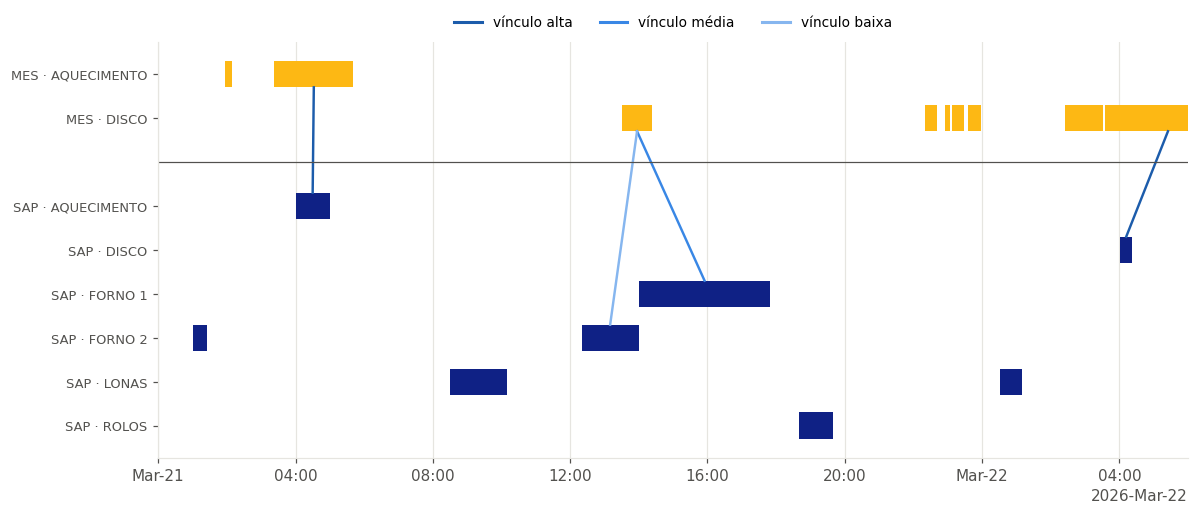

In [12]:
def dia_maquina(maquina, ini, fim, arq=None):
    ini, fim = pd.Timestamp(ini), pd.Timestamp(fim)
    pa = paradas[(paradas["maquina"] == maquina) & (paradas["fim"] >= ini) & (paradas["inicio"] <= fim)]
    so = vinculo[(vinculo["maquina"] == maquina) & (vinculo["fim"].fillna(vinculo["inicio"]) >= ini)
                 & (vinculo["inicio"] <= fim)]
    eqs_m = sorted(pa["equipamento"].unique())
    eqs_s = sorted(so["descricao_equip"].unique())
    y_m = {e: i for i, e in enumerate(eqs_m)}
    y_s = {e: len(eqs_m) + 1 + i for i, e in enumerate(eqs_s)}

    fig, ax = plt.subplots(figsize=(11, 0.42 * (len(y_m) + len(y_s) + 1) + 1))
    for _, r in pa.iterrows():
        ax.barh(y_m[r["equipamento"]], r["fim"] - r["inicio"], left=r["inicio"], height=0.6,
                color=COR_FONTE["MES"])
    centro = {r["id_parada"]: (r["inicio"] + (r["fim"] - r["inicio"]) / 2, y_m[r["equipamento"]])
              for _, r in pa.iterrows()}
    for _, o in so.iterrows():
        f = o["fim"] if pd.notna(o["fim"]) else o["inicio"] + pd.Timedelta(minutes=10)
        y = y_s[o["descricao_equip"]]
        ax.barh(y, f - o["inicio"], left=o["inicio"], height=0.6, color=COR_FONTE["SAP"])
        if pd.notna(o["id_parada"]) and o["id_parada"] in centro:
            x1, y1 = centro[o["id_parada"]]
            ax.plot([o["inicio"] + (f - o["inicio"]) / 2, x1], [y - 0.3, y1 + 0.3],
                    color=COR_CONF[o["confianca"]], lw=1.6)
    ax.axhline(len(eqs_m), color=TXT2, lw=0.8)
    ax.set_yticks(list(y_m.values()) + list(y_s.values()),
                  [f"MES · {e}" for e in eqs_m] + [f"SAP · {e}" for e in eqs_s], fontsize=8.5)
    ax.invert_yaxis(); ax.set_xlim(ini, fim)
    loc = mdates.AutoDateLocator(maxticks=10)
    ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax.grid(axis="y", visible=False)
    leg = [plt.Line2D([], [], color=COR_CONF[k], lw=2) for k in ["alta", "media", "baixa"]]
    ax.legend(leg, ["vínculo alta", "vínculo média", "vínculo baixa"], ncol=3, frameon=False,
              loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
    fig.tight_layout()
    if arq:
        fig.savefig(FIG_DIR / arq, bbox_inches="tight")
    plt.show()

dia_maquina("A", "2026-03-21 00:00", "2026-03-22 06:00", "06_um_dia_maquina_A.png")

## 7. Validação: como saber se o método acerta, sem gabarito?

Não existe uma lista oficial dizendo "esta ordem corresponde a esta parada". Por isso a validação é feita de três formas que se complementam, como três testemunhas independentes.

### 7.1 Sensibilidade: o resultado muda se mudarmos os números escolhidos?

O método tem vários "botões de ajuste" (tamanho da janela de busca, rapidez com que a nota cai com a distância, critério de âncora, limite de confiança, pesos das três pistas). Se o resultado mudasse muito ao girar um botão um pouco, ele seria **frágil**: dependeria de um número escolhido a dedo.

In [13]:
_, base = cc.conciliar(mes, paradas, sap)

def comparar(p):
    _, v = cc.conciliar(mes, paradas, sap, p)
    m = base.merge(v, on="n_ordem", suffixes=("_base", ""))
    lb, lv = m["id_parada_base"].notna(), m["id_parada"].notna()
    igual = (m["id_parada_base"] == m["id_parada"]) & lb
    return {"% ordens vinculadas": round(lv.mean() * 100, 1),
            "% alta": round((m["confianca"] == "alta").mean() * 100, 1),
            "% concordância c/ base": round((igual | (~lb & ~lv)).mean() * 100, 1),
            "ordens que trocam de parada": int((lb & lv & ~igual).sum())}

cenarios = {"base": {}}
for k, vals in {"JANELA_MAX_MIN": [120, 480], "TAU_GAP_MIN": [15, 60], "TAU_INICIO_MIN": [30, 120],
                "ANCORA_CONTENCAO": [0.3, 0.7], "SUPORTE_MIN_TOKEN": [2, 5], "LIMIAR_BAIXA": [0.40, 0.50]}.items():
    for x in vals:
        cenarios[f"{k} = {x}"] = {k: x}
for w in [(0.6, 0.2, 0.2), (0.4, 0.3, 0.3), (0.5, 0.35, 0.15), (0.5, 0.15, 0.35), (1.0, 0.0, 0.0)]:
    cenarios[f"pesos T/E/C = {w}"] = dict(zip(["W_T", "W_E", "W_C"], w))

sens = pd.DataFrame({nome: comparar({**P, **mud}) for nome, mud in cenarios.items()}).T
sens

,% ordens vinculadas,% alta,% concordância c/ base,ordens que trocam de parada
base,77.5,60.6,100.0,0.0
JANELA_MAX_MIN = 120,77.4,60.6,100.0,0.0
JANELA_MAX_MIN = 480,77.6,60.6,99.9,0.0
TAU_GAP_MIN = 15,77.1,60.4,100.0,0.0
TAU_GAP_MIN = 60,77.7,60.8,99.8,0.0
TAU_INICIO_MIN = 30,76.9,58.7,99.9,1.0
TAU_INICIO_MIN = 120,77.9,61.8,99.5,2.0
ANCORA_CONTENCAO = 0.3,77.5,60.8,99.9,1.0
ANCORA_CONTENCAO = 0.7,77.4,60.4,99.9,0.0
SUPORTE_MIN_TOKEN = 2,77.5,60.6,100.0,0.0


**Resultado:** variar janela, decaimentos, critério de âncora, suporte ou limiar muda **menos de 1%** dos vínculos. O resultado não é fruto de um número escolhido a dedo. O cenário **"só tempo"** (último da tabela, que zera os pesos de equipamento e texto) é o que mais muda: ordens trocam de parada. Isso mostra que equipamento e texto são o que desempata paradas que acontecem ao mesmo tempo.

### 7.2 Robustez a ruído: e se os horários fossem tão ruins quanto os da máquina A?

Nas máquinas B–D os pares de confiança alta são quase certos, então eles servem de "respostas conhecidas". O teste é **estragar de propósito** os horários do SAP e ver se o método ainda encontra os mesmos pares.

- Cada horário do SAP é empurrado para frente ou para trás por um valor sorteado. Os sorteios seguem uma **curva normal** (a "curva do sino"): a maioria dos empurrões é pequena e poucos são grandes. O tamanho típico do empurrão é o **desvio-padrão σ**, que testamos de 0 a 240 min.
- Para cada nível de σ, repetimos o sorteio **5 vezes** com sementes diferentes (a "semente" é o ponto de partida do sorteio; fixá-la permite repetir exatamente o mesmo experimento depois) e tiramos a média.
- Comparamos o método completo (horário + equipamento + texto) com uma versão que usa **só o horário**.

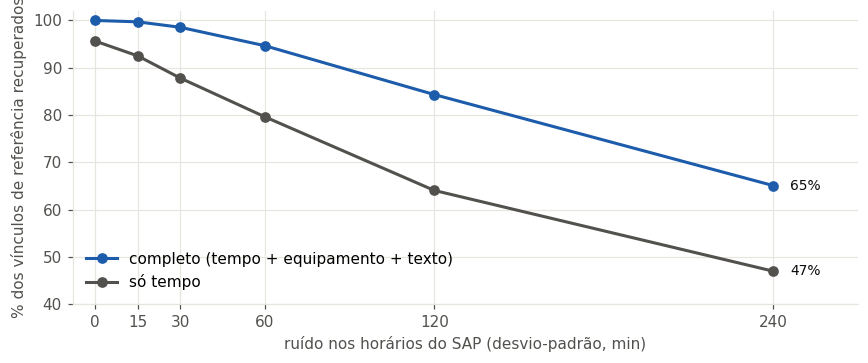

modelo,completo (tempo + equipamento + texto),só tempo
sigma_min,,
0,100.0,95.6
15,99.7,92.5
30,98.6,87.8
60,94.7,79.6
120,84.3,64.1
240,65.1,47.0


In [14]:
ref = base.merge(sap[["n_ordem", "maquina"]], on="n_ordem")
ref = ref[(ref["maquina"] != "A") & (ref["confianca"] == "alta")][["n_ordem", "id_parada"]]

linhas = []
for sigma in [0, 15, 30, 60, 120, 240]:
    for modelo, w in [("completo (tempo + equipamento + texto)", (0.5, 0.25, 0.25)), ("só tempo", (1.0, 0.0, 0.0))]:
        rec = []
        for seed in range(5):
            rs = np.random.RandomState(seed)
            s2 = sap.copy()
            desloc = pd.to_timedelta(rs.normal(0, sigma, len(s2)), unit="min")
            s2["inicio"] += desloc; s2["fim"] += desloc
            _, v = cc.conciliar(mes, paradas, s2, {**P, **dict(zip(["W_T", "W_E", "W_C"], w))})
            m = ref.merge(v, on="n_ordem", suffixes=("_ref", ""))
            rec.append((m["id_parada"] == m["id_parada_ref"]).mean() * 100)
        linhas.append({"sigma_min": sigma, "modelo": modelo, "recupera_%": np.mean(rec)})
rob = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(8, 3.4))
for (modelo, g), cor in zip(rob.groupby("modelo", sort=False), [COR_CONF["alta"], TXT2]):
    ax.plot(g["sigma_min"], g["recupera_%"], marker="o", ms=6, lw=2, color=cor, label=modelo)
    ax.text(g["sigma_min"].iloc[-1] + 6, g["recupera_%"].iloc[-1], f"{g['recupera_%'].iloc[-1]:.0f}%",
            va="center", fontsize=9, color=TXT)
ax.set_xticks(rob["sigma_min"].unique())
ax.set_xlabel("ruído nos horários do SAP (desvio-padrão, min)")
ax.set_ylabel("% dos vínculos de referência recuperados"); ax.set_ylim(40, 102); ax.set_xlim(-8, 270)
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_robustez_ruido.png", bbox_inches="tight")
plt.show()
rob.pivot(index="sigma_min", columns="modelo", values="recupera_%").round(1)

**Resultado:** com horários errados em cerca de 1 h para mais ou para menos, o método completo ainda recupera ~95% dos pares; usando só o horário, ~80%. Atenção: a referência é o próprio método completo sem ruído, então a curva mede **robustez** (o quanto o resultado aguenta dados piores), não acerto absoluto.

### 7.3 Auditoria humana

A terceira testemunha é uma pessoa. A fila de revisão (confiança baixa ou ambígua) e uma **amostra estratificada** dos pares de confiança alta e média vão para o arquivo `auditoria_conciliacao.xlsx`, com uma coluna `veredito` em branco para preencher.

**Amostra estratificada** quer dizer que sorteamos um pouco de **cada grupo** (até 8 por máquina e por nível de confiança), em vez de sortear tudo junto. É como uma pesquisa eleitoral que ouve gente de cada bairro, para que nenhum grupo fique de fora só porque é menor.

Conferir ~30 linhas da máquina A com quem conhece o equipamento dá a primeira medida real de acerto, e os pares confirmados viram novas âncoras (o método aprende com a correção).

In [15]:
cols = ["n_ordem", "maquina", "descricao_equip", "texto_padronizado", "inicio", "fim", "horas",
        "id_parada", "score", "S_tempo", "S_equip", "S_comp", "confianca", "ambiguo", "ordem_longa",
        "parada_2a", "score_2o"]
fila = vinculo.loc[vinculo["revisar"], cols]
amostra = (vinculo[vinculo["confianca"].isin(["alta", "media"])]
           .sample(frac=1, random_state=42)
           .groupby(["maquina", "confianca"]).head(8)[cols])
info_par = paradas.set_index("id_parada")[["equipamento", "inicio", "fim", "componente_dominante", "familia_dominante"]] \
                  .add_prefix("mes_")
auditoria = (pd.concat([fila.assign(origem="fila de revisão"), amostra.assign(origem="amostra")])
             .join(info_par, on="id_parada").assign(veredito=""))
print(f"Fila de revisão: {len(fila)} ordens | amostra: {len(amostra)}")

Fila de revisão: 88 ordens | amostra: 56


## 8. Exportação

Salvamos as tabelas de eventos, de vínculos (uma linha por ordem, com a parada atribuída, a nota e a confiança) e de todos os pares avaliados (para auditar qualquer nota). Também vão para o Excel o dicionário aprendido da máquina A e o teste de sensibilidade, e para um arquivo `.json` os parâmetros usados nesta rodada.

In [16]:
saidas = {
    "conc_eventos": eventos,     # 1 linha por evento (MES+SAP, MES sem SAP, SAP sem MES)
    "conc_vinculo": vinculo,     # 1 linha por ordem SAP válida -> parada atribuída, score, confiança
    "conc_pares": pares,         # todos os pares candidatos com as 3 evidências (auditoria do score)
}
for nome, df in saidas.items():
    try:
        df.to_parquet(OUT_DIR / f"{nome}.parquet", index=False)
    except ImportError:
        df.to_pickle(OUT_DIR / f"{nome}.pkl")

with pd.ExcelWriter(OUT_DIR / "conciliacao_inspecao.xlsx") as xw:
    eventos.to_excel(xw, sheet_name="eventos", index=False)
    vinculo.to_excel(xw, sheet_name="vinculo", index=False)
    depara.to_excel(xw, sheet_name="de-para aprendido A")
    sens.to_excel(xw, sheet_name="sensibilidade")
auditoria.to_excel(OUT_DIR / "auditoria_conciliacao.xlsx", index=False)

(OUT_DIR / "parametros_conciliacao.json").write_text(
    json.dumps({"gerado_em": pd.Timestamp.now().isoformat(timespec="seconds"), **P,
                "eventos": eventos["classe"].value_counts().to_dict()}, ensure_ascii=False, indent=2),
    encoding="utf-8")
print(eventos["classe"].value_counts())

classe
MES + SAP      1074
MES sem SAP     427
SAP sem MES     348
Name: count, dtype: int64


## 9. Limitações e próximos passos

- **Sem gabarito.** A confiança é uma nota construída pelas regras acima, não uma probabilidade medida contra respostas certas. A auditoria (7.3) é o caminho para medir o acerto de verdade.
- **Máquina A**: 55% das ordens não têm parada a menos de 4 h, e o algoritmo **não força** um par. Isso é o achado, não uma falha: ou a intervenção aconteceu sem parar a produção, ou a parada não foi anotada no MES. Só o acionamento digital (Subproduto 1), que cria um número comum para o evento nos dois sistemas, elimina essa dúvida na origem.
- **Ordens de calendário longo** (mais de 24 h) não informam o tempo real de serviço; ficam com confiança no máximo baixa.
- **Horário do SAP** é anotado à mão (arredondado na A); por isso `espera_ate_atuacao_min` é uma **aproximação** do tempo de resposta, não uma medição. Os valores negativos na A mostram exatamente isso.
- **Evolução**: incorporar os pares auditados como âncoras; usar o texto classificado do Subproduto 3 (componente / modo de falha) no lugar das palavras soltas; com o Subproduto 1, a conciliação passa a ser feita por número de chamado, e este algoritmo fica só para o histórico.

# 10. Referências

Fellegi, I. P.; Sunter, A. B. “A Theory for Record Linkage”. Journal of the American Statistical Association, v. 64, n. 328, p. 1183–1210, dez. 1969. *(Artigo clássico que formalizou a ideia de ligar registros de bases diferentes somando "pesos de evidência" de vários campos, que é a base da nota usada aqui.)*

Ratner, A.; Bach, S. H.; Ehrenberg, H.; Fries, J.; Wu, S.; Ré, C. “Snorkel: rapid training data creation with weak supervision”. The VLDB Journal, v. 29, n. 2, p. 709–730, 2020. DOI: 10.1007/s00778-019-00552-1. *(Mostra como aprender sem gabarito a partir de exemplos "fáceis" gerados por regras, a mesma ideia das âncoras.)*